In [6]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511026/notebook

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511026/notebook


In [7]:
import os, sys
print("Folder kerja     :", os.getcwd())
print("Drive tersambung :", os.path.exists("/content/drive/MyDrive"))
src = "/content/drive/MyDrive/simuteh-2330511026/src"
print("Folder src ada   :", os.path.exists(src))
if os.path.exists(src):
    print("Isi src          :", os.listdir(src))
print("src ada di path  :", src in sys.path)

Folder kerja     : /content/drive/MyDrive/simuteh-2330511026/notebook
Drive tersambung : True
Folder src ada   : True
Isi src          : ['__pycache__', 'praproses.py', 'utils_tepi.py', 'utils_cv.py', 'bercak.py']
src ada di path  : True


In [8]:
import importlib, sys
sys.path.insert(0, "/content/drive/MyDrive/simuteh-2330511026/src")

importlib.invalidate_caches()
sys.modules.pop("utils_cv", None)

from utils_cv import baca, tampil
print("utils_cv berhasil dimuat dari:", sys.modules["utils_cv"].__file__)

utils_cv berhasil dimuat dari: /content/drive/MyDrive/simuteh-2330511026/src/utils_cv.py


In [9]:
import sys, json
sys.path.insert(0, "/content/drive/MyDrive/simuteh-2330511026/src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")


def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb


def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

lembar kerja 3.1

In [10]:
B = np.array([[0,0,0,0,0,0,0,0,0],
              [0,1,1,1,0,0,0,0,0],
              [0,1,0,1,0,0,0,1,0],
              [0,1,1,1,0,0,0,0,0],
              [0,0,0,0,1,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,1,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0]], np.uint8)
se = np.ones((3,3), np.uint8)
kw = dict(borderType=cv2.BORDER_CONSTANT, borderValue=0)

print("komponen 4 dan 8:", cv2.connectedComponents(B, connectivity=4)[0]-1,
      cv2.connectedComponents(B, connectivity=8)[0]-1)
print("erosi:\n", cv2.erode(B, se, **kw))
print("opening:\n", cv2.morphologyEx(B, cv2.MORPH_OPEN, se, **kw))
closing = cv2.morphologyEx(B, cv2.MORPH_CLOSE, se, **kw)
print("closing:\n", closing)
print("closing lalu opening:\n", cv2.morphologyEx(closing, cv2.MORPH_OPEN, se, **kw))

komponen 4 dan 8: 4 3
erosi:
 [[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
opening:
 [[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
closing:
 [[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]
closing lalu opening:
 [[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]


Kode 3.1 Mask daun awal dan bercak awal

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.998                   202               8           0.455
1  teh_021.png          0.998                   152               1           0.065
2  teh_011.png          0.997                   132               0               -


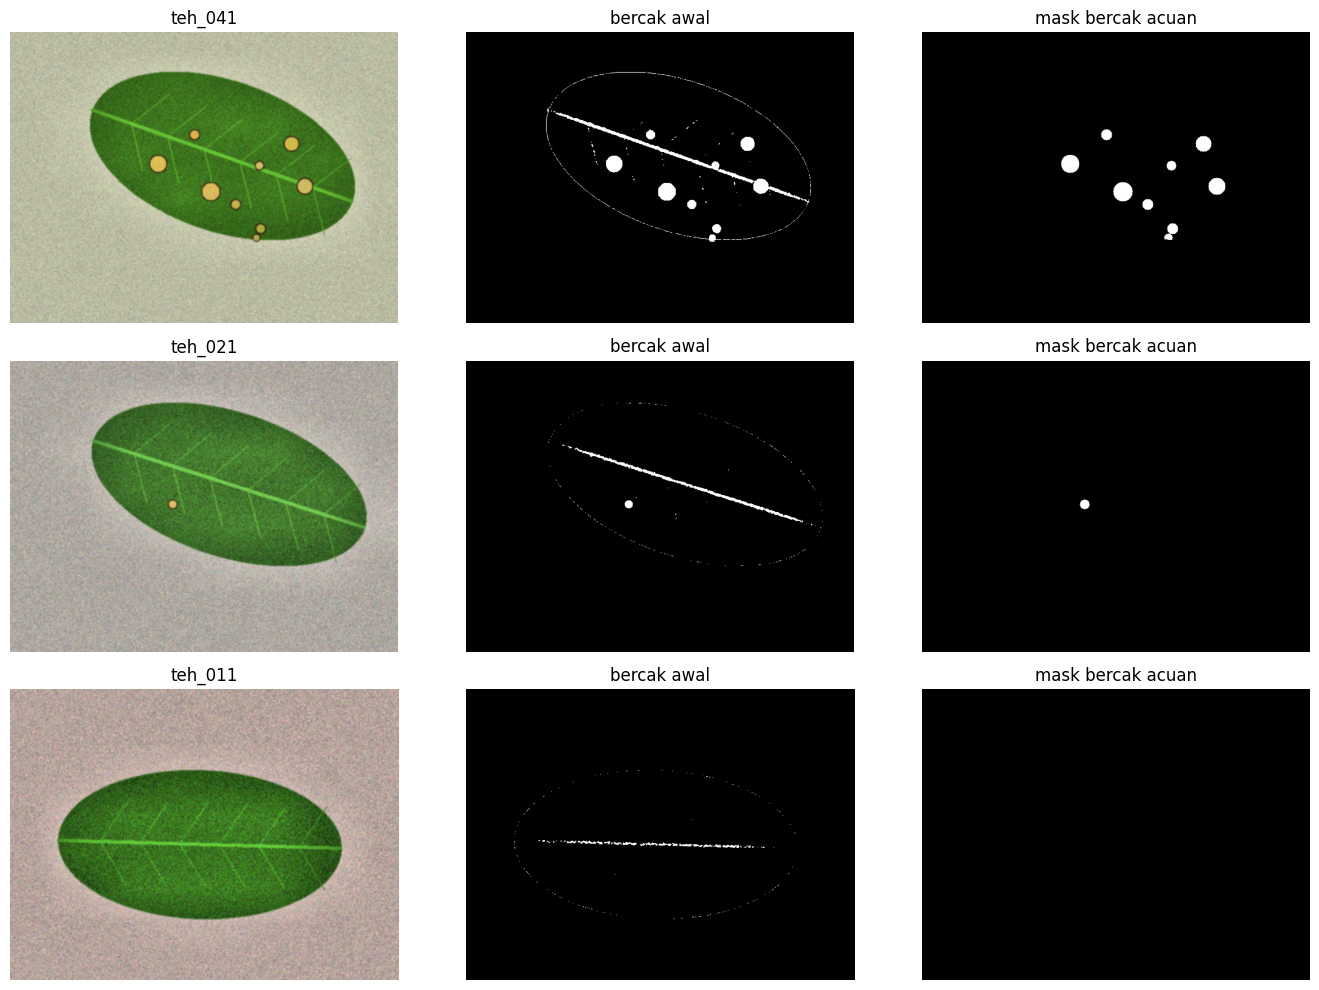

In [11]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:   # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

Kode 3.2 Erosi, dilasi, opening, dan closing

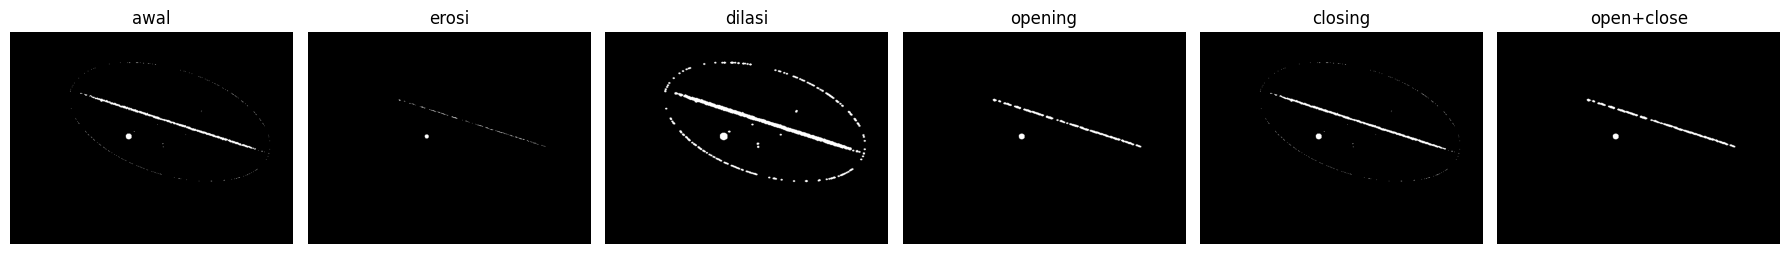

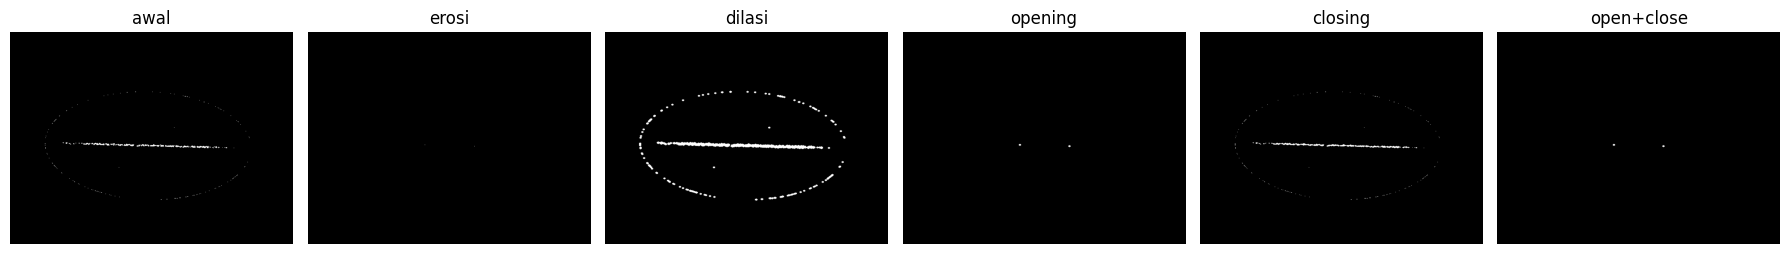

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       152    2115  0.065
1   teh_021.png       erosi        50     296   0.16
2   teh_021.png      dilasi        68    6256  0.031
3   teh_021.png     opening        15    1500   0.09
4   teh_021.png     closing       152    2184  0.063
5   teh_021.png  open+close        11    1539  0.088
6   teh_011.png        awal       132    1000      -
7   teh_011.png       erosi         2       2      -
8   teh_011.png      dilasi        67    4301      -
9   teh_011.png     opening         2      34      -
10  teh_011.png     closing       112    1120      -
11  teh_011.png  open+close         2      34      -


In [12]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3)); plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

Kode 3.3 Eksperimen k, bentuk, dan ukuran SE

In [13]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas",
                      values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.61   0.16        12.05  27.15  20.50
          5       0.64   0.23         2.45   3.70   3.95
          7       0.69   0.40         1.60   2.85   1.80
  persegi 3       0.62   0.18         5.65   7.40   8.90
          5       0.66   0.29         2.90   3.30   3.55
          7       0.69   0.45         0.70   0.60   0.00
  silang  3       0.61   0.16        12.05  27.15  20.50
          5       0.64   0.22         4.55   6.00   6.75
          7       0.70   0.37         3.40   4.40   3.90
4 elips   3       0.64   0.25         8.50  10.05  13.15
          5       0.66   0.35         2.70   4.25   2.90
          7       0.68   0.48         0.85   0.70   0.25
  persegi 3       0.65   0.27         4.70   6.10   6.85
          5       0.67   0.45         1.85   1.75   1.45
          7       0.66   0.41  

In [14]:
t9 = eks[eks.k == 4].pivot_table(index=["bentuk", "ukuran"], columns="kelas",
                                 values=["IoU", "galat_jumlah"]).round(2)
print(t9)

                 IoU        galat_jumlah              
kelas          berat ringan        berat ringan  sehat
bentuk  ukuran                                        
elips   3       0.64   0.25         8.50  10.05  13.15
        5       0.66   0.35         2.70   4.25   2.90
        7       0.68   0.48         0.85   0.70   0.25
persegi 3       0.65   0.27         4.70   6.10   6.85
        5       0.67   0.45         1.85   1.75   1.45
        7       0.66   0.41         0.75   0.75   0.00
silang  3       0.64   0.25         8.50  10.05  13.15
        5       0.66   0.34         4.40   6.25   5.05
        7       0.69   0.44         1.65   1.15   0.60


Kode 3.4 Gradien morfologi dibandingkan dengan Canny

In [15]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))   # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
      .groupby("kondisi").mean().round(3))

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.841     0.707
gelap                          0.983     0.684
kontras_rendah                 0.171     0.905
normal                         0.992     0.691
terang                         0.927     0.718


In [16]:
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

langkah 3.6

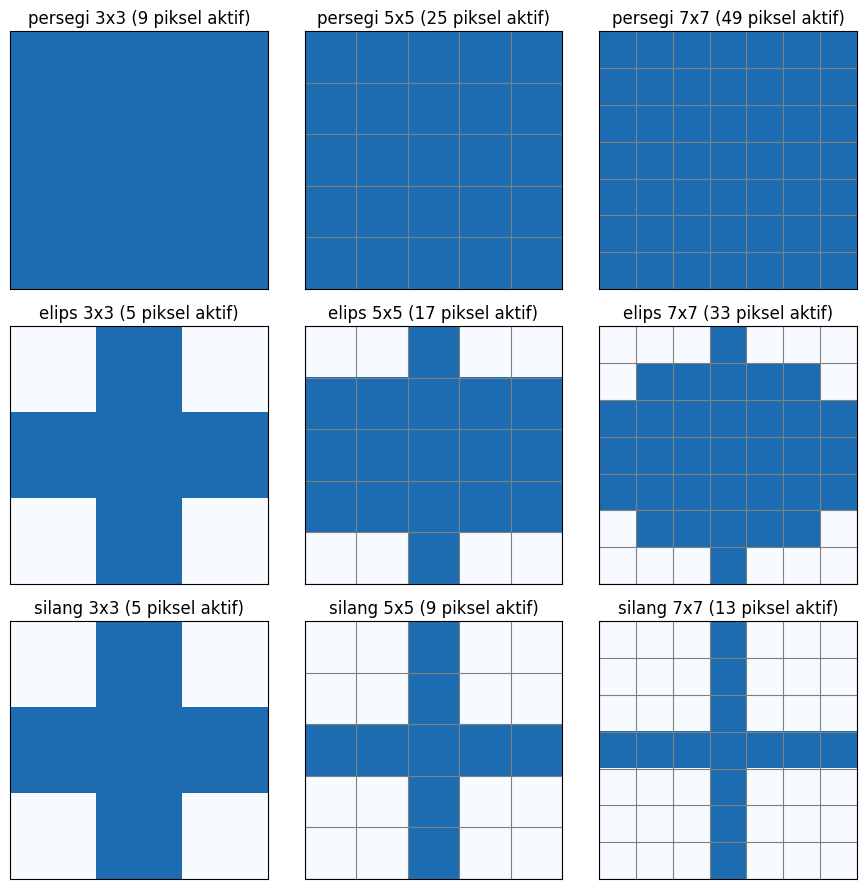

In [17]:
bentuk_se = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
ukuran_se = [3, 5, 7]

plt.figure(figsize=(9, 9))
i = 1
for nb, kb in bentuk_se.items():
    for uk in ukuran_se:
        se = cv2.getStructuringElement(kb, (uk, uk))
        ax = plt.subplot(3, 3, i)
        ax.imshow(se, cmap="Blues", vmin=0, vmax=1.3)
        ax.set_xticks(np.arange(-0.5, uk, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, uk, 1), minor=True)
        ax.grid(which="minor", color="gray", linewidth=0.8)
        ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)
        ax.set_title(f"{nb} {uk}x{uk} ({int(se.sum())} piksel aktif)")
        i += 1
plt.tight_layout()
plt.savefig("../hasil/p6_panel_se.png", dpi=150)
plt.show()

Kode 4.1 Komponen terhubung dan pengukuran setiap bercak

konektivitas 4: 9 komponen
konektivitas 8: 9 komponen
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0      1       17      3.25         13.7       1.15         1.25  155  135
1      2     2511    480.62        888.4       0.04        15.99  373  212
2      3      182     34.84         47.5       1.02         1.00  304  168
3      4      435     83.26         74.5       0.98         1.00  464  184
4      5      598    114.46         88.4       0.96         1.04  243  217
5      6      690    132.07         93.8       0.98         1.00  330  263
6      7      180     34.45         46.6       1.04         1.00  371  283
7      8      174     33.30         46.6       1.01         1.00  412  323
8      9      108     20.67         36.7       1.01         1.10  405  339


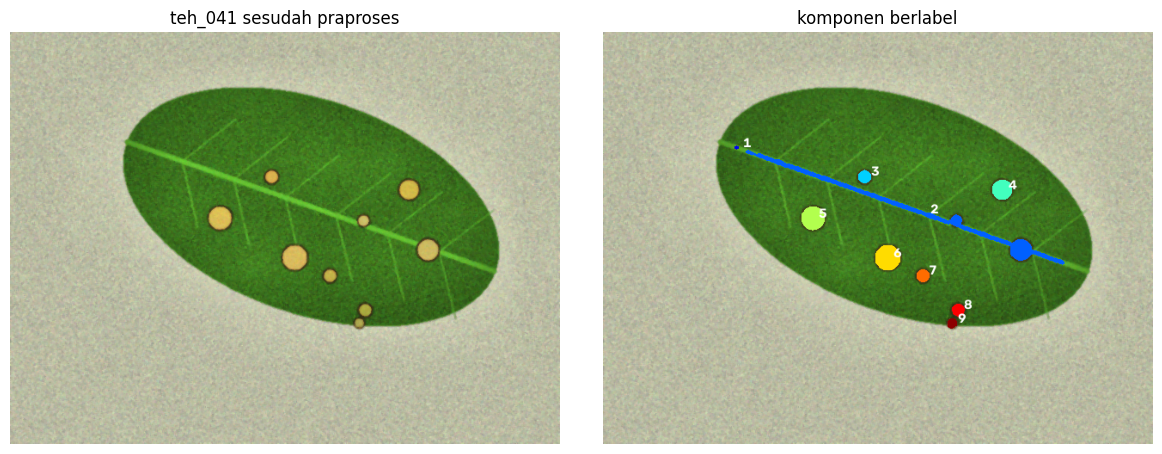

In [18]:
MM_PER_PX = 0.4375  # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px


def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8),
                                                       connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1),
                      round(kebulatan, 2), round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan",
             "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl


img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))

for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")

tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

Kode 4.2 Penyaringan komponen berdasarkan ukuran dan bentuk

In [19]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos


aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])

uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
print(uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2))
print("Daun sehat yang masih memiliki bercak palsu:")
print(uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum())

kelas                     berat  ringan  sehat
aturan                                        
luas + kebulatan           1.60    1.90   1.30
luas + kebulatan + rasio   1.05    1.05   0.65
luas >= 20                 1.95    3.00   2.25
tanpa saring               2.70    4.25   2.90
Daun sehat yang masih memiliki bercak palsu:
aturan
luas + kebulatan             8
luas + kebulatan + rasio     5
luas >= 20                   9
tanpa saring                10
Name: palsu, dtype: int64


4.4

status
benar    195
palsu    191
Name: count, dtype: int64


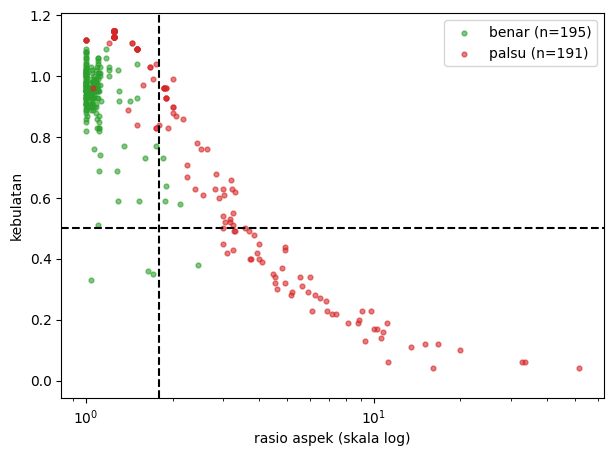

In [20]:
kom = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    tk, lb = ukur_komponen(bersih)
    for _, r in tk.iterrows():
        benar = (mb[lb == r.label] > 0).mean() > 0.5   # lebih dari separuh piksel ada di mask acuan
        kom.append([d.nama_file, d.kelas, r.luas_px, r.kebulatan, r.rasio_aspek,
                    "benar" if benar else "palsu"])

komp = pd.DataFrame(kom, columns=["nama", "kelas", "luas", "kebulatan", "rasio", "status"])
print(komp.status.value_counts())

plt.figure(figsize=(7, 5))
for st, warna in [("benar", "tab:green"), ("palsu", "tab:red")]:
    s = komp[komp.status == st]
    plt.scatter(s.rasio, s.kebulatan, s=12, alpha=0.6, c=warna, label=f"{st} (n={len(s)})")
plt.axhline(0.5, ls="--", c="k")
plt.axvline(1.8, ls="--", c="k")
plt.xscale("log")
plt.xlabel("rasio aspek (skala log)")
plt.ylabel("kebulatan")
plt.legend()
plt.savefig("../hasil/p6_sebar_komponen.png", dpi=150)
plt.show()

Kode 5.1 Kerangka src/bercak.py

In [21]:
%%writefile /content/drive/MyDrive/simuteh-2330511026/src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,            # kanal terpilih (2 = R)
    "k": 4.0,              # ambang median + k x MAD
    "se_bentuk": "elips",  # "elips", "persegi", "silang"
    "se_open": 5,          # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,         # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,        # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,   # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,    # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}

_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    # TODO 1: opening bila se_open > 0
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    # TODO 2: closing bila se_close > 0
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    keluar, daftar = np.zeros_like(biner), []
    # TODO 3: label komponen terhubung (konektivitas 8)
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8),
                                                       connectivity=8)
    for i in range(1, n):
        # TODO 4: luas, keliling, kebulatan, rasio aspek
        mask_i = (lbl == i).astype(np.uint8)
        kontur, _ = cv2.findContours(mask_i, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        luas = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * luas / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        # TODO 5: simpan hanya yang memenuhi luas_min, bulat_min, rasio_maks
        if luas >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({
                "luas_px": luas,
                "luas_mm2": round(luas * p["mm_per_px"] ** 2, 2),
                "keliling_px": round(float(keliling), 1),
                "kebulatan": round(float(kebulatan), 2),
                "rasio_aspek": round(float(rasio), 2),
                "pusat": (int(cen[i][0]), int(cen[i][1])),
            })
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    # TODO 6: persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    persen = 100.0 * int((m_bercak > 0).sum()) / luas_daun if luas_daun > 0 else 0.0
    # TODO 7: kelas dari batas_ringan dan batas_berat
    if persen < p["batas_ringan"]:
        kelas = "Sehat"
    elif persen < p["batas_berat"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Bercak Berat"
    return {"mask_daun": m_daun, "mask_bercak": m_bercak, "jumlah_bercak": len(daftar),
            "persen_bercak": round(float(persen), 3), "kelas": kelas, "bercak": daftar}


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)

Overwriting /content/drive/MyDrive/simuteh-2330511026/src/bercak.py


Kode 5.2 Evaluasi modul bercak.py

Galat absolut rerata persen bercak: 0.574
Korelasi persen prediksi vs acuan : 0.954
Akurasi kelas : 0.9
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             18              2      0
Bercak Ringan             0             16      4
Sehat                     0              0     20
kondisi
bayangan          0.83
gelap             1.00
kontras_rendah    0.75
normal            1.00
terang            0.92
Name: benar, dtype: float64


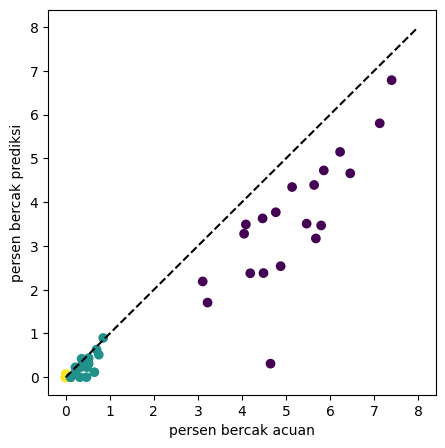

In [22]:
import importlib, bercak
importlib.reload(bercak)

PB = {"k": 3, "se_bentuk": "elips", "se_open": 7, "se_close": 7, "luas_min": 50}
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])

ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan",
                                  "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))

plt.figure(figsize=(5, 5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("persen bercak acuan")
plt.ylabel("persen bercak prediksi")
plt.savefig("../hasil/p6_sebar_persen.png", dpi=150)
plt.show()

Langkah 5.3

       nama        kondisi  persen_acuan  persen_prediksi   kelas_acuan kelas_prediksi
teh_025.png       bayangan          0.11            0.000 Bercak Ringan          Sehat
teh_029.png kontras_rendah          0.47            0.000 Bercak Ringan          Sehat
teh_030.png       bayangan          0.11            0.000 Bercak Ringan          Sehat
teh_039.png kontras_rendah          0.32            0.000 Bercak Ringan          Sehat
teh_044.png kontras_rendah          4.65            0.310  Bercak Berat  Bercak Ringan
teh_048.png         terang          3.22            1.706  Bercak Berat  Bercak Ringan


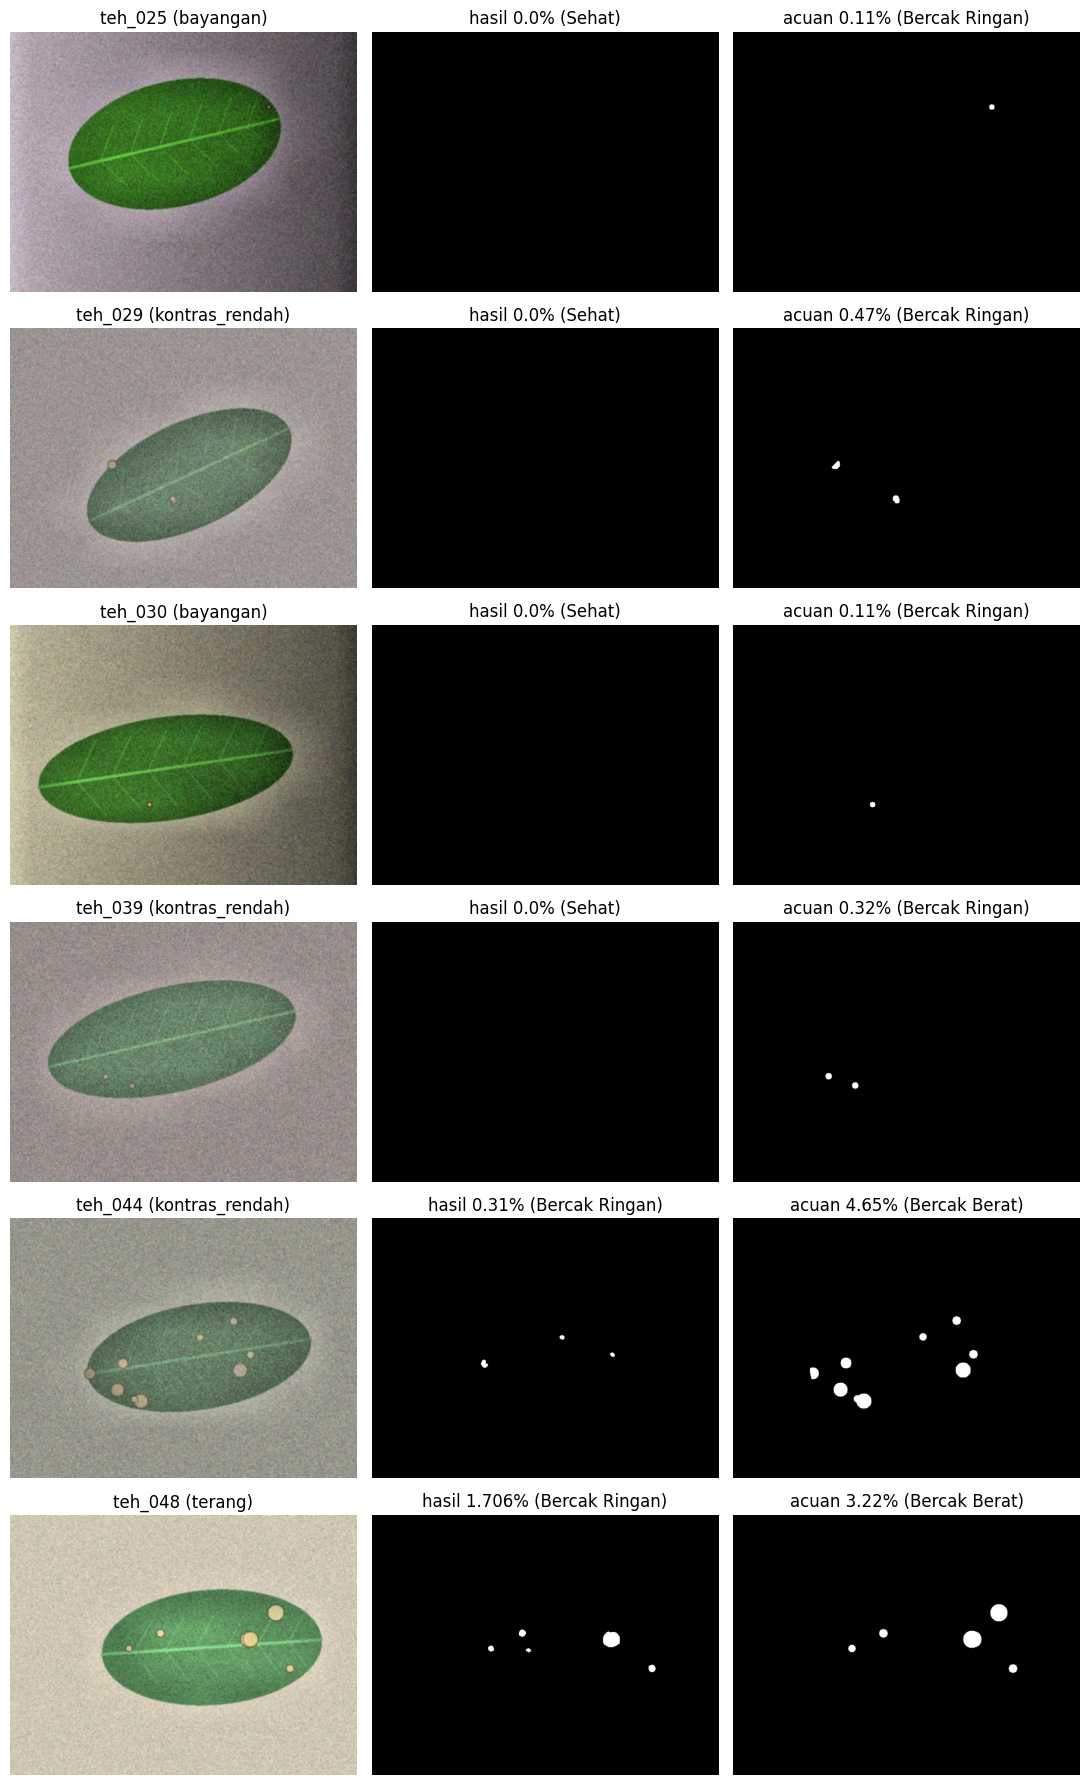

In [23]:
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
print(salah[["nama", "kondisi", "persen_acuan", "persen_prediksi",
             "kelas_acuan", "kelas_prediksi"]].to_string(index=False))

panel, judul = [], []
for _, r in salah.iterrows():
    img, md, mb = muat(r.nama)
    pra_ = praproses(img, PARAM)
    h = bercak.analisis_daun(pra_, PB)
    panel += [pra_, h["mask_bercak"], mb]
    judul += [f"{r.nama[:7]} ({r.kondisi})",
              f"hasil {r.persen_prediksi}% ({r.kelas_prediksi})",
              f"acuan {r.persen_acuan}% ({r.kelas_acuan})"]

tampil(panel, judul, baris=len(salah), ukuran=(11, 3 * len(salah)))
plt.savefig("../hasil/p6_citra_salah.png", dpi=100)
plt.show()

Langkah 5.4 Justifikasi parameter.

In [24]:
pras = {}
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pras[d.nama_file] = praproses(img, PARAM)

peta_kelas = {"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"}


def evaluasi(PB):
    baris = []
    for _, d in label.iterrows():
        h = bercak.analisis_daun(pras[d.nama_file], PB)
        baris.append([d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"], h["kelas"]])
    e = pd.DataFrame(baris, columns=["kelas", "kondisi", "pa", "pp", "kp"])
    e["ka"] = e.kelas.map(peta_kelas)
    kr = e[e.kondisi == "kontras_rendah"]
    return [(e.kp == e.ka).mean(), (e.pp - e.pa).abs().mean(),
            ((e.ka == "Sehat") & (e.kp != "Sehat")).sum(),
            ((e.ka != "Sehat") & (e.kp == "Sehat")).sum(),
            (kr.kp == kr.ka).mean()]


hasil = []
for k in [3, 4, 6]:
    for bentuk, uk in [("elips", 5), ("elips", 7), ("persegi", 5), ("persegi", 7)]:
        for lm in [20, 50, 100]:
            PB_uji = {"k": k, "se_bentuk": bentuk, "se_open": uk, "se_close": uk, "luas_min": lm}
            hasil.append([k, bentuk, uk, lm, *evaluasi(PB_uji)])

grid = pd.DataFrame(hasil, columns=["k", "bentuk", "se", "luas_min", "akurasi", "galat_persen",
                                    "sehat_jadi_bercak", "bercak_jadi_sehat", "akurasi_kontras_rendah"])
print(grid.sort_values(["akurasi", "galat_persen"], ascending=[False, True]).head(10).round(3))
grid.to_csv("../hasil/p6_grid_parameter.csv", index=False)

    k   bentuk  se  luas_min  akurasi  galat_persen  sehat_jadi_bercak  bercak_jadi_sehat  akurasi_kontras_rendah
4   3    elips   7        50    0.900         0.574                  0                  4                   0.750
7   3  persegi   5        50    0.883         0.597                  0                  4                   0.750
16  4    elips   7        50    0.883         0.622                  0                  6                   0.667
9   3  persegi   7        20    0.883         0.637                  0                  4                   0.667
19  4  persegi   5        50    0.883         0.638                  0                  5                   0.667
1   3    elips   5        50    0.883         0.648                  0                  4                   0.750
3   3    elips   7        20    0.867         0.571                  4                  2                   0.750
0   3    elips   5        20    0.867         0.638                  1                  